# Normalize sqY2H consensus scores

This script applies various QA/QC steps and then computes a normalized interaction score. For QA/QC we:

1.   Check whether 6 media controls on each mega-plate meet various condition-specific thresholds
2.   Check for autoactivation mating failures
3.   Adjust consensus score based on autoactivation score and filter if score invalid

# Automated

In [135]:
import polars as pl 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [136]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_inputs = "../../../1_allele_collection/1_inputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = 0
rrs_id = 999999.0

In [137]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [138]:
scores = pd.read_csv(f"{outputs_dir}/2_automated_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control'] == True]
scores = scores[scores['media_control'] == False]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# Fix data types before converting to polars
scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

scores_before_seq = scores.clone()

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,455.65623,false,8.982013,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A04""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,544.3046,false,9.215059,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,505.925513,false,9.118748,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A06""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,536.567345,false,9.196153,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,279.0,null,11451.0,9.99999e5,"""RRS_VUS1_DB_1""","""B01""","""RRS_VUS1_AD_1""","""B01""",4.0,498.666689,false,9.099786,532.80656,"""CALCOCO2""",null,null,null,null,null,null,null,null,null,"""11451.0_999999.0""","""11451.0_999999.0_LW_VUSAPWT1B1""","""279.0_11451.0_999999.0_VUSAPWT…","""279.0_11451.0_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P18""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,53212.0,null,54308.0,218853.0,"""VUSMutY8Dh022""","""G09""","""CEGSint_Y8A_7""","""F04""",2.0,412.423535,false,8.853071,178.228434,"""ROPN1""","""PKP2""","""Ala372Pro""","""1114G>C""","""ENSG00000057294""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""PKP2_Ala372Pro""","""54308.0_218853.0""","""54308.0_218853.0_LWAH1_VUSAPWT…","""53212.0_54308.0_218853.0_VUSAP…","""53212.0_54308.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""P19""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00069191e8,null,54308.0,218854.0,"""VUSMutY8Dh022""","""H09""","""CEGSint_Y8A_6""","""E11""",2.0,659.198706,false,9.470046,null,"""SPTA1""","""PKP2""","""Phe424Ser""","""1271T>C""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Phe424Ser""","""54308.0_218854.0""","""54308.0_218854.0_LWAH1_VUSAPWT…","""100069191.0_54308.0_218854.0_V…","""100069191.0_54308.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""P20""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B

In [139]:
def get_filtering_stats(scores_df, aa_id, rrs_id, step_name=""):
    """
    Get filtering statistics for a scores dataframe and return as dictionary
    
    Parameters:
    scores_df: polars DataFrame with the scores data
    aa_id: autoactivation ID to exclude 
    rrs_id: RRS ID to exclude
    step_name: optional name for the filtering step
    
    Returns:
    dict: Dictionary containing various counts
    """
    
    # Filter for non-autoactivation, non-RRS entries
    filtered_scores = scores_df.filter(
        (pl.col("ad_orf_id") != aa_id) & 
        (pl.col("db_mut_id") != rrs_id)
    )
    
    stats = {
        'step_name': step_name,
        'total_rows': scores_df.shape[0],
        'ppi_groups': filtered_scores.select(pl.col("ppi_group").n_unique()).item(),
        'db_orf_ids': filtered_scores.select(pl.col("db_orf_id").n_unique()).item(),
        'ad_orf_ids': filtered_scores.select(pl.col("ad_orf_id").n_unique()).item(),
        'db_groups': filtered_scores.select(pl.col("db_group").n_unique()).item(),
        'edge_groups': filtered_scores.select(pl.col("edge_group").n_unique()).item()
    }
    
    # Add counts for db_orf_ids with both WT and variants
    try:
        # Find db_orf_ids with WT data
        db_orfs_with_wt = filtered_scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique()
        
        # Find db_orf_ids with variant data  
        db_orfs_with_variants = filtered_scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique()
        
        # Get intersection - db_orf_ids that have both WT and variants
        db_orfs_with_both = db_orfs_with_wt.join(
            db_orfs_with_variants, 
            on="db_orf_id", 
            how="inner"
        )
        
        stats['db_orfs_with_wt'] = db_orfs_with_wt.height
        stats['db_orfs_with_variants'] = db_orfs_with_variants.height  
        stats['db_orfs_with_both_wt_and_variants'] = db_orfs_with_both.height
        
        # Filter to only include db_orf_ids that have both WT and variants
        scores_both = scores_df.filter(pl.col("db_orf_id").is_in(db_orfs_with_both.select("db_orf_id").to_series().to_list()))
        filtered_scores_both = scores_both.filter(
            (pl.col("ad_orf_id") != aa_id) & 
            (pl.col("db_mut_id") != rrs_id)
        )
        
        # Get ALL the statistics for the WT+variant filtered dataset
        stats['ppi_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("ppi_group").n_unique()).item()
        stats['db_orf_ids_with_both_wt_variants'] = filtered_scores_both.select(pl.col("db_orf_id").n_unique()).item()
        stats['ad_orf_ids_with_both_wt_variants'] = filtered_scores_both.select(pl.col("ad_orf_id").n_unique()).item()
        stats['db_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("db_group").n_unique()).item()
        stats['edge_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("edge_group").n_unique()).item()
        
    except Exception as e:
        print(f"Warning: Could not calculate WT/variant stats for {step_name}: {e}")
        stats['db_orfs_with_wt'] = None
        stats['db_orfs_with_variants'] = None
        stats['db_orfs_with_both_wt_and_variants'] = None
        stats['ppi_groups_with_both_wt_variants'] = None
        stats['db_orf_ids_with_both_wt_variants'] = None
        stats['ad_orf_ids_with_both_wt_variants'] = None
        stats['db_groups_with_both_wt_variants'] = None
        stats['edge_groups_with_both_wt_variants'] = None
    
    return stats

def create_comprehensive_filtering_table(filtering_stats_list):
    """
    Create a comprehensive table showing all filtering steps with counts and percentages
    """
    import pandas as pd
    
    # Initialize the summary table
    summary_data = []
    
    for i, stats in enumerate(filtering_stats_list):
        if i == 0:
            # First step - no previous comparison
            row = {
                'Step': stats['step_name'],
                'Total_Rows': stats['total_rows'],
                'PPI_Groups': stats['ppi_groups'],
                'DB_ORF_IDs': stats['db_orf_ids'],
                'AD_ORF_IDs': stats['ad_orf_ids'],
                'DB_Groups': stats['db_groups'],
                'Edge_Groups': stats['edge_groups'],
                'DB_ORFs_Both_WT_Variants': stats.get('db_orfs_with_both_wt_and_variants', 'N/A'),
                'PPI_Groups_Both': stats.get('ppi_groups_with_both_wt_variants', 'N/A'),
                'DB_ORF_IDs_Both': stats.get('db_orf_ids_with_both_wt_variants', 'N/A'),
                'AD_ORF_IDs_Both': stats.get('ad_orf_ids_with_both_wt_variants', 'N/A'),
                'DB_Groups_Both': stats.get('db_groups_with_both_wt_variants', 'N/A'),
                'Edge_Groups_Both': stats.get('edge_groups_with_both_wt_variants', 'N/A'),
                'Rows_Dropped': 0,
                'PPIs_Dropped': 0,
                'DB_ORFs_Dropped': 0,
                'AD_ORFs_Dropped': 0,
                'DB_Groups_Dropped': 0,
                'Edge_Groups_Dropped': 0,
                'DB_ORFs_Both_Dropped': 0,
                'PPI_Groups_Both_Dropped': 0,
                'DB_ORF_IDs_Both_Dropped': 0,
                'AD_ORF_IDs_Both_Dropped': 0,
                'DB_Groups_Both_Dropped': 0,
                'Edge_Groups_Both_Dropped': 0,
                'Percent_Rows_Dropped': 0.0,
                'Percent_PPIs_Dropped': 0.0,
                'Percent_DB_ORFs_Dropped': 0.0,
                'Percent_AD_ORFs_Dropped': 0.0,
                'Percent_DB_Groups_Dropped': 0.0,
                'Percent_Edge_Groups_Dropped': 0.0,
                'Percent_DB_ORFs_Both_Dropped': 0.0,
                'Percent_PPI_Groups_Both_Dropped': 0.0,
                'Percent_DB_ORF_IDs_Both_Dropped': 0.0,
                'Percent_AD_ORF_IDs_Both_Dropped': 0.0,
                'Percent_DB_Groups_Both_Dropped': 0.0,
                'Percent_Edge_Groups_Both_Dropped': 0.0
            }
        else:
            # Compare with previous step
            prev_stats = filtering_stats_list[i-1]
            
            rows_dropped = prev_stats['total_rows'] - stats['total_rows']
            ppis_dropped = prev_stats['ppi_groups'] - stats['ppi_groups']
            db_orfs_dropped = prev_stats['db_orf_ids'] - stats['db_orf_ids']
            ad_orfs_dropped = prev_stats['ad_orf_ids'] - stats['ad_orf_ids']
            db_groups_dropped = prev_stats['db_groups'] - stats['db_groups']
            edge_groups_dropped = prev_stats['edge_groups'] - stats['edge_groups']
            
            # Handle WT/variant specific drops for ALL metrics
            db_orfs_both_dropped = 0
            ppi_groups_both_dropped = 0
            db_orf_ids_both_dropped = 0
            ad_orf_ids_both_dropped = 0
            db_groups_both_dropped = 0
            edge_groups_both_dropped = 0
            
            if (prev_stats.get('db_orfs_with_both_wt_and_variants') is not None and 
                stats.get('db_orfs_with_both_wt_and_variants') is not None):
                db_orfs_both_dropped = prev_stats['db_orfs_with_both_wt_and_variants'] - stats['db_orfs_with_both_wt_and_variants']
                ppi_groups_both_dropped = prev_stats['ppi_groups_with_both_wt_variants'] - stats['ppi_groups_with_both_wt_variants']
                db_orf_ids_both_dropped = prev_stats['db_orf_ids_with_both_wt_variants'] - stats['db_orf_ids_with_both_wt_variants']
                ad_orf_ids_both_dropped = prev_stats['ad_orf_ids_with_both_wt_variants'] - stats['ad_orf_ids_with_both_wt_variants']
                db_groups_both_dropped = prev_stats['db_groups_with_both_wt_variants'] - stats['db_groups_with_both_wt_variants']
                edge_groups_both_dropped = prev_stats['edge_groups_with_both_wt_variants'] - stats['edge_groups_with_both_wt_variants']
            
            row = {
                'Step': stats['step_name'],
                'Total_Rows': stats['total_rows'],
                'PPI_Groups': stats['ppi_groups'],
                'DB_ORF_IDs': stats['db_orf_ids'],
                'AD_ORF_IDs': stats['ad_orf_ids'],
                'DB_Groups': stats['db_groups'],
                'Edge_Groups': stats['edge_groups'],
                'DB_ORFs_Both_WT_Variants': stats.get('db_orfs_with_both_wt_and_variants', 'N/A'),
                'PPI_Groups_Both': stats.get('ppi_groups_with_both_wt_variants', 'N/A'),
                'DB_ORF_IDs_Both': stats.get('db_orf_ids_with_both_wt_variants', 'N/A'),
                'AD_ORF_IDs_Both': stats.get('ad_orf_ids_with_both_wt_variants', 'N/A'),
                'DB_Groups_Both': stats.get('db_groups_with_both_wt_variants', 'N/A'),
                'Edge_Groups_Both': stats.get('edge_groups_with_both_wt_variants', 'N/A'),
                'Rows_Dropped': rows_dropped,
                'PPIs_Dropped': ppis_dropped,
                'DB_ORFs_Dropped': db_orfs_dropped,
                'AD_ORFs_Dropped': ad_orfs_dropped,
                'DB_Groups_Dropped': db_groups_dropped,
                'Edge_Groups_Dropped': edge_groups_dropped,
                'DB_ORFs_Both_Dropped': db_orfs_both_dropped,
                'PPI_Groups_Both_Dropped': ppi_groups_both_dropped,
                'DB_ORF_IDs_Both_Dropped': db_orf_ids_both_dropped,
                'AD_ORF_IDs_Both_Dropped': ad_orf_ids_both_dropped,
                'DB_Groups_Both_Dropped': db_groups_both_dropped,
                'Edge_Groups_Both_Dropped': edge_groups_both_dropped,
                'Percent_Rows_Dropped': round((rows_dropped / prev_stats['total_rows']) * 100, 2) if prev_stats['total_rows'] > 0 else 0,
                'Percent_PPIs_Dropped': round((ppis_dropped / prev_stats['ppi_groups']) * 100, 2) if prev_stats['ppi_groups'] > 0 else 0,
                'Percent_DB_ORFs_Dropped': round((db_orfs_dropped / prev_stats['db_orf_ids']) * 100, 2) if prev_stats['db_orf_ids'] > 0 else 0,
                'Percent_AD_ORFs_Dropped': round((ad_orfs_dropped / prev_stats['ad_orf_ids']) * 100, 2) if prev_stats['ad_orf_ids'] > 0 else 0,
                'Percent_DB_Groups_Dropped': round((db_groups_dropped / prev_stats['db_groups']) * 100, 2) if prev_stats['db_groups'] > 0 else 0,
                'Percent_Edge_Groups_Dropped': round((edge_groups_dropped / prev_stats['edge_groups']) * 100, 2) if prev_stats['edge_groups'] > 0 else 0,
                'Percent_DB_ORFs_Both_Dropped': round((db_orfs_both_dropped / prev_stats['db_orfs_with_both_wt_and_variants']) * 100, 2) if prev_stats.get('db_orfs_with_both_wt_and_variants', 0) > 0 else 0,
                'Percent_PPI_Groups_Both_Dropped': round((ppi_groups_both_dropped / prev_stats['ppi_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('ppi_groups_with_both_wt_variants', 0) > 0 else 0,
                'Percent_DB_ORF_IDs_Both_Dropped': round((db_orf_ids_both_dropped / prev_stats['db_orf_ids_with_both_wt_variants']) * 100, 2) if prev_stats.get('db_orf_ids_with_both_wt_variants', 0) > 0 else 0,
                'Percent_AD_ORF_IDs_Both_Dropped': round((ad_orf_ids_both_dropped / prev_stats['ad_orf_ids_with_both_wt_variants']) * 100, 2) if prev_stats.get('ad_orf_ids_with_both_wt_variants', 0) > 0 else 0,
                'Percent_DB_Groups_Both_Dropped': round((db_groups_both_dropped / prev_stats['db_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('db_groups_with_both_wt_variants', 0) > 0 else 0,
                'Percent_Edge_Groups_Both_Dropped': round((edge_groups_both_dropped / prev_stats['edge_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('edge_groups_with_both_wt_variants', 0) > 0 else 0
            }
        
        summary_data.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(summary_data)
    
    return df

In [140]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])


# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

final_sequencing_df = pd.read_csv(f"{meta_outputs}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)

final_sequencing_df

# Convert final_sequencing_df to polars and ensure matching data types
final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "db_seq_final"])

# Join the db_seq_final column onto scores
scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")

print(f"Scores shape: {scores.shape}")
print(f"Unique values in db_seq_final: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")


scores_aa_rrs = scores.filter(
    (pl.col("ad_orf_id") == aa_id) | 
    (pl.col("db_mut_id") == rrs_id)
)

scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
    (
        (pl.col("db_mut_id") == 0) |  # WT is always good
        (pl.col("db_seq_final") == "Y")  # Use the final Y/N decision from sequence confirmation
    )
)

scores = pl.concat([scores, scores_aa_rrs])

print("After sequence confirmation filtering:")
print(f"Scores shape: {scores.shape}")
print(f"Unique db_seq_final values: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")

scores
scores_after_seq = scores.clone()

Scores shape: (285965, 38)
Unique values in db_seq_final: ['Y', None, 'N']
After sequence confirmation filtering:
Scores shape: (193138, 38)
Unique db_seq_final values: [None, 'N', 'Y']


In [141]:
scores_pd = scores.to_pandas()
scores_pd

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final
0,VUSAPWT1B1r01_001,A15,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,11805,0,DisWTGDEh03,C04,CEGSint_Y8A_1,C01,4.0,528.001331,False,9.174929,558.350679,SMURF2,SMAD3,None,None,ENSG00000166949,None,None,NaN,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,None
1,VUSAPWT1B1r01_001,A16,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,11805,0,DisWTGDEh03,C04,CEGSint_Y8A_1,C01,4.0,595.377806,False,9.334000,558.350679,SMURF2,SMAD3,None,None,ENSG00000166949,None,None,NaN,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,None
2,VUSAPWT1B1r01_001,A17,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,70497,0,DisWTGDEh03,D04,CEGSint_Y8A_5,H07,4.0,585.556892,False,9.311877,586.988591,CYSRT1,AGXT,None,None,ENSG00000172482,None,None,NaN,NaN,AGXT,70497.0_0.0,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None
3,VUSAPWT1B1r01_001,A18,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,70497,0,DisWTGDEh03,D04,CEGSint_Y8A_5,H07,4.0,603.194803,False,9.351370,586.988591,CYSRT1,AGXT,None,None,ENSG00000172482,None,None,NaN,NaN,AGXT,70497.0_0.0,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None
4,VUSAPWT1B1r01_001,A23,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,11567,NaN,52920,0,DisWTGDEh03,A05,CEGSint_Y8A_5,A06,4.0,572.135977,False,9.281086,578.211793,TAX1BP1,LITAF,None,None,ENSG00000189067,None,None,NaN,NaN,LITAF,52920.0_0.0,52920.0_0.0_LW_VUSAPWT1B1,11567.0_52920.0_0.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193133,VUSAPWT1B1r06_036,P06,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,13295,218058,VUSMutY8Dh022,H03,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,5.643856,1.149346,empty_ad,TTPA,His101Gln,303T>G,ENSG00000137561,CEGS2,1_Pathogenic,NaN,2.0,TTPA_His101Gln,13295.0_218058.0,13295.0_218058.0_LWAH1_VUSAPWT1B1,0.0_13295.0_218058.0_VUSAPWT1B1,0.0_13295.0_VUSAPWT1B1,None,0,Y
193134,VUSAPWT1B1r06_036,P09,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,2595,999999,RRS_VUS1_DB_2,F05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,5.643856,0.000000,empty_ad,None,None,None,None,None,None,NaN,NaN,None,2595.0_999999.0,2595.0_999999.0_LWAH1_VUSAPWT1B1,0.0_2595.0_999999.0_VUSAPWT1B1,0.0_2595.0_VUSAPWT1B1,None,None,None
193135,VUSAPWT1B1r06_036,P10,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,2595,999999,RRS_VUS1_DB_2,F05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,5.643856,0.000000,empty_ad,None,None,None,None,None,None,NaN,NaN,None,2595.0_999999.0,2595.0_999999.0_LWAH1_VUSAPWT1B1,0.0_2595.0_999999.0_VUSAPWT1B1,0.0_2595.0_VUSAPWT1B1,None,None,None
193136,VUSAPWT1B1r06_036,P11,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,7167,999999,RRS_VUS1_DB_2,H05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,5.643856,117.067323,empty_ad,None,None,None,None,None,None,NaN,NaN,None,7167.0_999999.0,7167.0_999999.0_LWAH1_VUSAPWT1B1,0.0_7167.0_999999.0_VUSAPWT1B1,0.0_7167.0_VUSAPWT1B1,None,None,None


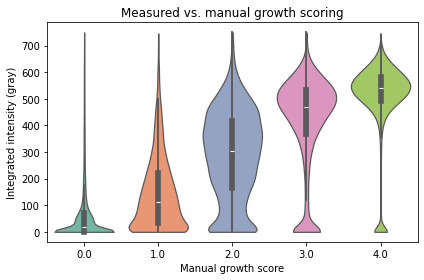

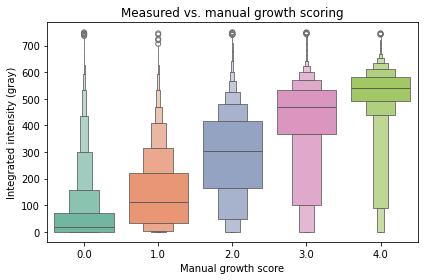

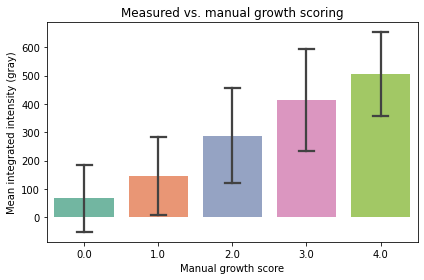

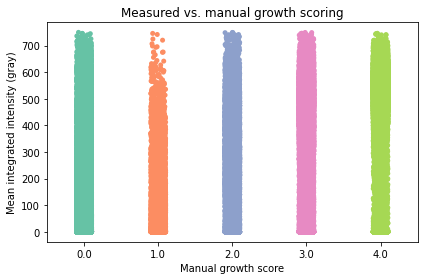

In [142]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

scores_pd = scores_pd.dropna(subset=['manual_score_growth']).copy()


# Plot
y      = scores_pd['manual_score_growth'].astype(int)

# Violin
plt.figure(figsize=(6, 4))
sns.violinplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    inner='box',         
    density_norm='width',
    cut=0,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# plt.ylim(0, 1800) # Trim outliers on plot
# Export plot
# violinValidationPlotPath = os.path.join(PATH, "violin_plot_validation_against_GT.png")
# plt.savefig(violinValidationPlotPath, dpi=300)
plt.show()

# Boxen
plt.figure(figsize=(6, 4))
sns.boxenplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
# plt.ylim(0, 1500) # Trim outliers on the plot
plt.xlabel('Manual growth score')
plt.ylabel('Integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# boxenValidationPlotPath = os.path.join(PATH, "boxen_plot_validation_against_GT.png")
# plt.savefig(boxenValidationPlotPath, dpi=300)
plt.show()

# Bar
plt.figure(figsize=(6, 4))
sns.barplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    errorbar='sd',   
    capsize=0.2,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Mean integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# barValidationPlotPath = os.path.join(PATH, "bar_plot_validation_against_GT.png")
# plt.savefig(barValidationPlotPath, dpi=300)
plt.show()


# swarmplot
plt.figure(figsize=(6, 4))
sns.stripplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    # errorbar='sd',   
    # capsize=0.2,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Mean integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# barValidationPlotPath = os.path.join(PATH, "bar_plot_validation_against_GT.png")
# plt.savefig(barValidationPlotPath, dpi=300)
plt.show()

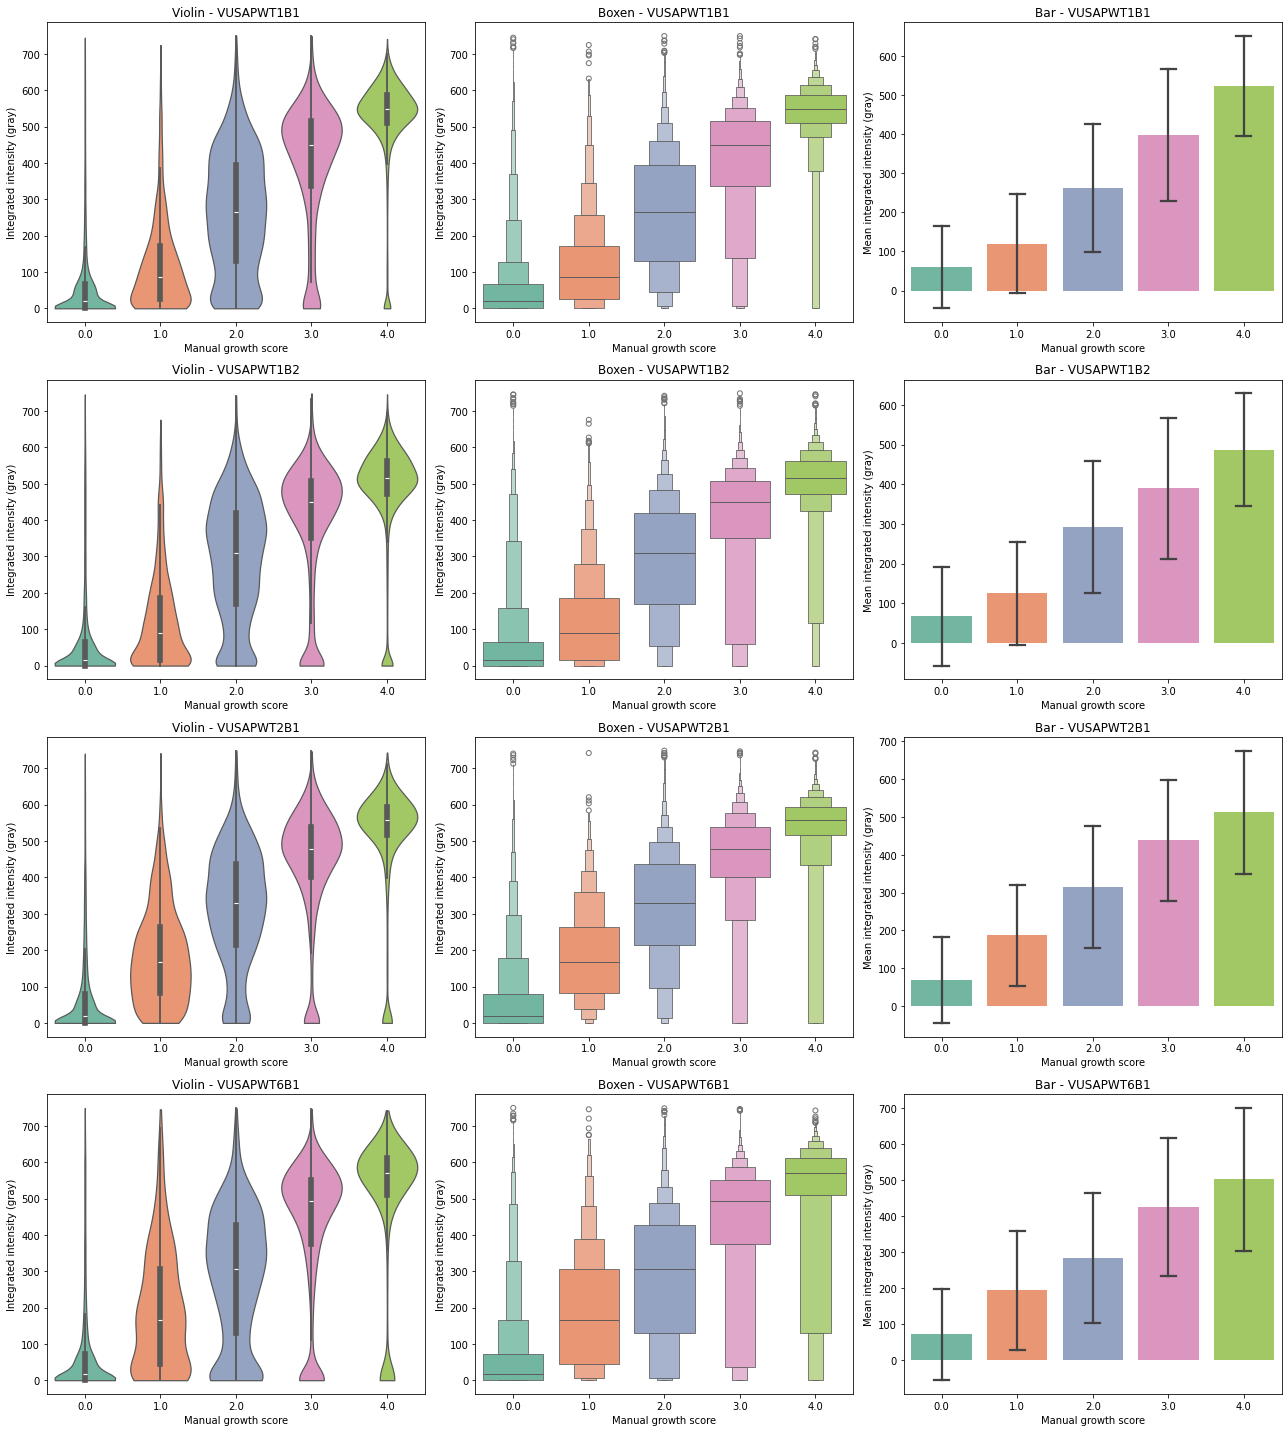

In [143]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

scores_pd = scores_pd.dropna(subset=['manual_score_growth']).copy()

# Get unique retest_batch values
unique_batches = scores_pd['retest_batch'].unique()
n_batches = len(unique_batches)

# Create figure with subplots: rows = batches, columns = 3 plot types
fig, axes = plt.subplots(n_batches, 3, figsize=(18, 5*n_batches))

# If only one batch, make sure axes is 2D
if n_batches == 1:
    axes = axes.reshape(1, -1)

plot_types = ['Violin', 'Boxen', 'Bar']

for i, batch in enumerate(unique_batches):
    batch_data = scores_pd[scores_pd['retest_batch'] == batch].copy()
    
    if len(batch_data) == 0:
        # Hide empty subplots
        for j in range(3):
            axes[i, j].set_visible(False)
        continue
    
    # Violin plot
    sns.violinplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        inner='box',         
        density_norm='width',
        cut=0,
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 0]
    )
    axes[i, 0].set_xlabel('Manual growth score')
    axes[i, 0].set_ylabel('Integrated intensity (gray)')
    axes[i, 0].set_title(f'Violin - {batch}')

    # Boxen plot
    sns.boxenplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 1]
    )
    axes[i, 1].set_xlabel('Manual growth score')
    axes[i, 1].set_ylabel('Integrated intensity (gray)')
    axes[i, 1].set_title(f'Boxen - {batch}')

    # Bar plot
    sns.barplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        errorbar='sd',   
        capsize=0.2,
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 2]
    )
    axes[i, 2].set_xlabel('Manual growth score')
    axes[i, 2].set_ylabel('Mean integrated intensity (gray)')
    axes[i, 2].set_title(f'Bar - {batch}')

plt.tight_layout()
plt.show()

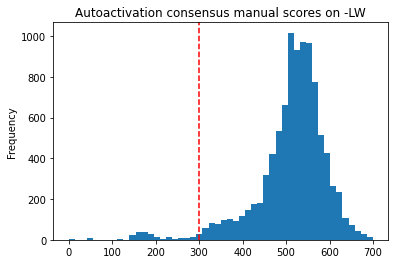

In [144]:
scores_pd = scores.to_pandas()

scores_pd[
    (scores_pd.ad_orf_id == aa_id) &
    (scores_pd.condition_name == 'LW')
].consensus_score.plot(kind='hist', bins=50, title='Autoactivation consensus manual scores on -LW')
plt.axvline(x=300, color='red', linestyle='--', label='Threshold')

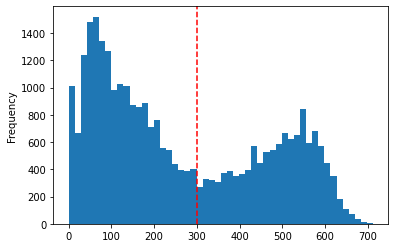

In [145]:

scores_pd[
    # (scores_pd.ad_orf_id == aa_id) &
    (scores_pd.condition_name == 'LWH1')
].consensus_score.plot(kind='hist', bins=50)#, title='Autoactivation consensus manual scores on -LW')
plt.axvline(x=300, color='red', linestyle='--', label='Threshold')

In [146]:
# print('Before filtering:')
# print(scores.shape)
# print('ppi_group', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ppi_group").n_unique()).item())
# print('db_orf_ids', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("db_orf_id").n_unique()).item())
# print('ad_orf_ids', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ad_orf_id").n_unique()).item())
# print('db_groups', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("db_group").n_unique()).item())
# print('edge_groups', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("edge_group").n_unique()).item())



# Usage example - replace your current print statements with:
# stats_before = get_filtering_stats(scores, aa_id, rrs_id, "Before filtering")
# print_filtering_stats(stats_before)

# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))

print('After aa mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))

print('After aa mating failure other media:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))


print('After mating failure LW step 1:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# Takes care of cases of mating failures where the consensus score is null
mating_failures_2 = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))

print('After mating failure LW step 2:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))

# Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")  # or .first() if you want the first value
)

# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")

print('remove aa rows:?')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# substract aa values or
# remove if aa value > x (300)?

scores_adjusted = scores.with_columns(
    (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
).filter(
   ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
)

print('after adjusted score:')
print(scores_adjusted.shape)
print('ppis', scores_adjusted.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

# alternative approach, remove rows where aa score is greater than 300
scores_300 = scores.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))

print('after aa > 300:')
print(scores_300.shape)
print('ppis', scores_300.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


scores = scores_300
scores

After aa mating failure LW:
(184043, 38)
ppis 4373
nodes 244
ads 777
48
After aa mating failure other media:
(184043, 38)
ppis 4373
nodes 244
ads 777
48
After mating failure LW step 1:
(177947, 38)
ppis 4151
nodes 244
ads 757
48
After mating failure LW step 2:
(156270, 38)
ppis 3648
nodes 232
ads 695
0
remove aa rows:?
(100989, 39)
ppis 3648
nodes 232
ads 695
0
after adjusted score:
(60689, 40)
ppis 3263
nodes 232
ads 695
after aa > 300:
(84017, 39)
ppis 3636
nodes 232
ads 695
0


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_016""","""A01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,631.349047,false,9.41225,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""A02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,597.499373,false,9.338735,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""B01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,559.39349,false,9.25123,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""B02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,523.231397,false,9.162974,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""E01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_5""","""A06""",4.0,635.023557,false,9.42001,584.419307,"""TAX1BP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""11567.0_52920.0_2678.0_VUSAPWT…","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_021""","""N16""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,100002000,null,2922,999999,"""RRS_VUS1_DB_2""","""B09""","""RRS_VUS1_AD_2""","""B09""",0.0,10.47451,false,5.918255,18.464379,"""TSPYL2""",null,null,null,null,null,null,null,null,null,"""2922.0_999999.0""","""2922.0_999999.0_LWAH1_VUSAPWT1…","""100002000.0_2922.0_999999.0_VU…","""100002000.0_2922.0_VUSAPWT1B1""","""NULL""",null,null,0.0
"""VUSAPWT1B1r06_021""","""O01""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,7880,null,3980,999999,

In [147]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_016""","""A01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,631.349047,false,9.41225,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""A02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,597.499373,false,9.338735,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""B01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,559.39349,false,9.25123,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""B02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,523.231397,false,9.162974,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""E01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_5""","""A06""",4.0,635.023557,false,9.42001,584.419307,"""TAX1BP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""11567.0_52920.0_2678.0_VUSAPWT…","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P16""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,3598,null,52920,218637,"""VUSMutY8Dh022""","""F07""","""CEGSint_Y8A_6""","""B02""",2.0,null,false,null,null,"""DAZAP2""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""52920.0_218637.0""","""52920.0_218637.0_LWAH1_VUSAPWT…","""3598.0_52920.0_218637.0_VUSAPW…","""3598.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",0.0
"""VUSAPWT1B1r06_036""","""P19""","""VUSAPWT1B1r06_031_032_033_034_…","""VU

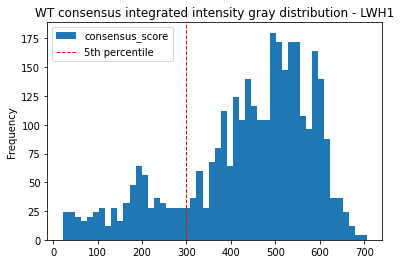

In [148]:
scores_pd = scores.to_pandas()
fig = scores_pd[(scores_pd['db_mut_id'] == 0) &
                (scores_pd['condition_name'] == 'LWH1')].consensus_score.plot(kind='hist', bins=50, title='WT consensus integrated intensity gray distribution - LWH1')

plt.axvline(300, color='red', linestyle='dashed', linewidth=1, label='5th percentile')
plt.legend()

In [149]:
# Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                            .filter(pl.col("db_mut_id") == 0)
                            .filter(pl.col("consensus_score") < 300)
                            .select('edge_group')
                            .to_series().unique().to_list())
scores_dropped = scores.filter(pl.col("edge_group").is_in(wt_failures))
scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))

print('removing WT failures:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


wt_failures

removing WT failures:
(59538, 39)
ppis 2965
nodes 204
ads 633


['10159.0_5431.0_VUSAPWT2B1',
 '100011481.0_13554.0_VUSAPWT2B1',
 '10793.0_5645.0_VUSAPWT6B1',
 '820.0_3581.0_VUSAPWT1B2',
 '9746.0_8416.0_VUSAPWT1B2',
 '11452.0_5712.0_VUSAPWT6B1',
 '70835.0_3689.0_VUSAPWT1B2',
 '824.0_8514.0_VUSAPWT1B2',
 '71963.0_71258.0_VUSAPWT6B1',
 '9625.0_14019.0_VUSAPWT1B2',
 '824.0_13597.0_VUSAPWT1B2',
 '100070143.0_5718.0_VUSAPWT1B2',
 '53626.0_2448.0_VUSAPWT2B1',
 '5793.0_2922.0_VUSAPWT2B1',
 '11452.0_4723.0_VUSAPWT6B1',
 '56585.0_7198.0_VUSAPWT6B1',
 '7912.0_4062.0_VUSAPWT2B1',
 '3148.0_71191.0_VUSAPWT6B1',
 '13662.0_1485.0_VUSAPWT1B2',
 '100015297.0_13554.0_VUSAPWT6B1',
 '8239.0_9634.0_VUSAPWT2B1',
 '11670.0_54230.0_VUSAPWT6B1',
 '100070143.0_53965.0_VUSAPWT1B2',
 '100080816.0_4062.0_VUSAPWT6B1',
 '10844.0_7198.0_VUSAPWT6B1',
 '55647.0_12132.0_VUSAPWT1B2',
 '2260.0_7323.0_VUSAPWT2B1',
 '12310.0_56108.0_VUSAPWT6B1',
 '53030.0_71258.0_VUSAPWT2B1',
 '11539.0_2713.0_VUSAPWT6B1',
 '11830.0_7675.0_VUSAPWT2B1',
 '100064146.0_13554.0_VUSAPWT1B2',
 '10352.0_11032.0

In [150]:
scores_pd = scores.to_pandas()

scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score


In [151]:
# write out results
scores.write_csv(f"{outputs_dir}/3_automated_qaqc_consensus_scores.csv")

In [152]:
# Summing scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

# First, sum adjusted scores across conditions for each variant
summed_scores = summed_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("consensus_score").sum().alias("summed_consensus_score")
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

# Get WT scores (db_mut_id == 0) for normalization
wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
]).rename({"summed_consensus_score": "wt_summed_score"})

# Join variant scores with their corresponding WT scores
summed_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference
)
# .select([
#     "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", 
#     "summed_consensus_score", "wt_summed_score", 'condition_name'
# ])

# Join back with original to get condition names
summed_scores = summed_scores.join(
    original_conditions,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

summed_scores = summed_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

summed_scores = summed_scores.with_columns(
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.String),
        pl.col('db_orf_id').cast(pl.String),
        pl.col('db_mut_id').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

summed_scores

204
204
195


ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group
i64,i64,i64,str,f64,f64,str,str,str
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH25""","""1""","""1868_3535_201190_VUSAPWT1B1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWA""","""1""","""1868_3535_201190_VUSAPWT1B1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH1""","""1""","""1868_3535_201190_VUSAPWT1B1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH10""","""1""","""1868_3535_201190_VUSAPWT1B1"""
11922,2713,200824,"""VUSAPWT1B1""",5977.872038,5303.926931,"""LWA""","""1""","""11922_2713_200824_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…
55351,2920,214433,"""VUSAPWT1B2""",649.166028,2905.724269,"""LWA""","""1""","""55351_2920_214433_VUSAPWT1B2"""
70989,55864,0,"""VUSAPWT6B1""",6234.842046,6234.842046,"""LWH1""","""6""","""70989_55864_0_VUSAPWT6B1"""
70989,55864,0,"""VUSAPWT6B1""",6234.842046,6234.842046,"""LWA""","""6""","""70989_55864_0_VUSAPWT6B1"""


In [153]:
print(summed_scores.shape)
print('ppis', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


(9259, 9)
ppis 2359
nodes 204
ads 633


In [154]:
# cast all to same format
summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

summed_scores = summed_scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
summed_scores = summed_scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")


# Filter to only keep interactions where both ad and db are confirmed
summed_scores = summed_scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db
i64,i64,i64,str,f64,f64,str,str,str,str,str
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH25""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWA""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH1""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH10""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1"""
11922,2713,200824,"""VUSAPWT1B1""",5977.872038,5303.926931,"""LWA""","""1""","""11922_2713_200824_VUSAPWT1B1""","""1""","""1"""
…,…,…,…,…,…,…,…,…,…,…
55351,2920,214433,"""VUSAPWT1B2""",649.166028,2905.724269,"""LWA""","""1""","""55351_2920_214433_VUSAPWT1B2""","""1""","""1"""
70989,55864,0,"""VUSAPWT6B1""",6234.842046,6234.842046,"""LWH1""","""6""","""70989_55864_0_VUSAPWT6B1""","""1""","""1"""
70989,55864,0,"""VUSAPWT6B1""",6234.842046,6234.842046,"""LWA""","""6""","""70989_55864_0_VUSAPWT6B1""","""1""","""1"""


In [155]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol
i64,i64,i64,str,f64,f64,str,str,str,str,str,str
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH25""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1""","""FATE1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWA""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1""","""FATE1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH1""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1""","""FATE1"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH10""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1""","""FATE1"""
11922,2713,200824,"""VUSAPWT1B1""",5977.872038,5303.926931,"""LWA""","""1""","""11922_2713_200824_VUSAPWT1B1""","""1""","""1""","""MYOG"""
…,…,…,…,…,…,…,…,…,…,…,…
55351,2920,214433,"""VUSAPWT1B2""",649.166028,2905.724269,"""LWA""","""1""","""55351_2920_214433_VUSAPWT1B2""","""1""","""1""","""TP53BP2"""
70989,55864,0,"""VUSAPWT6B1""",6234.842046,6234.842046,"""LWH1""","""6""","""70989_55864_0_VUSAPWT6B1""","""1""","""1""","""FAM209A"""
70989,55864,0,"""VUSAPWT6B1""",6234.842046,6234.842046,"""LWA""","""6""","""70989_55864_0_VUSAPWT6B1""","""1""","""1""","""FAM209A"""


In [156]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

summed_scores = summed_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH25""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1""","""FATE1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWA""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1""","""FATE1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH1""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1""","""FATE1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val"""
1868,3535,201190,"""VUSAPWT1B1""",8462.168953,5901.925685,"""LWH10""","""1""","""1868_3535_201190_VUSAPWT1B1""","""1""","""1""","""FATE1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val"""
11922,2713,200824,"""VUSAPWT1B1""",5977.872038,5303.926931,"""LWA""","""1""","""11922_2713_200824_VUSAPWT1B1""","""1""","""1""","""MYOG""","""MLH1""","""Ser106Arg""","""318C>G""","""ENSG00000076242""","""CEGS2""","""4_VUS""",null,1.0,"""MLH1_Ser106Arg"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
55351,2920,214433,"""VUSAPWT1B2""",649.166028,2905.724269,"""LWA""","""1""","""55351_2920_214433_VUSAPWT1B2""","""1""","""1""","""TP53BP2""","""GFAP""","""Ala364Pro""","""1090G>C""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Ala364Pro"""
70989,55864,0,"""VUSAPWT6B1""",6234.842046,6234.842046,"""LWH1""","""6""","""70989_55864_0_VUSAPWT6B1""","""1""","""1""","""FAM209A""","""ADIPOQ""",null,null,"""ENSG00000181092""",null,null,null,null,"""ADIPOQ"""
70989,55864,0,"""VUSAPWT6B1""",6234.842046,6234.842046,"""LWA""","""6""","""70989_55864_0_VUSAPWT6B1""","""1""","""1""","""FAM209A""","""ADIPOQ""",null,null,"""ENSG00000181092""",null,null,null,null,"""ADIPOQ"""


In [157]:
print(summed_scores.shape)
print('ppis', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())


(9259, 21)
ppis 2359


In [158]:
# Create a filtered version for saving - keep only one row per unique combination
summed_scores_for_export = summed_scores.unique(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
summed_scores_for_export
# Write the filtered version (with only 1 row per combination)
summed_scores_for_export.write_csv(f"{outputs_dir}/4_automated_normalized_consensus_scores.csv")

In [159]:
summed_scores = summed_scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

In [160]:
# =============================================================================
# COMPREHENSIVE FILTERING WORKFLOW TRACKING - POST-PROCESSING ANALYSIS
# =============================================================================

print("Reconstructing filtering workflow for comprehensive tracking...")
print("Note: This analysis recreates the filtering steps to track statistics")
print("="*80)

# Initialize tracking list
filtering_stats_list = []

# We need to start from before filtering and recreate the workflow
# Read the original scores before any filtering
print("Loading original scores to reconstruct filtering workflow...")

# Start by loading the original data before filtering

# Recreate the filtering workflow step by step
current_scores = scores_before_seq.clone()

# Step 0: Before any filtering (original data)
filtering_stats_list.append(get_filtering_stats(current_scores, aa_id, rrs_id, "0. Original Data"))

# Step 1: After sequence filtering (this is approximately where we start in the current workflow)
# We'll use a proxy since we can't perfectly recreate the sequence filtering
# The current 'scores' variable represents the state after sequence filtering
filtering_stats_list.append(get_filtering_stats(scores_after_seq, aa_id, rrs_id, "1. After Sequencing QC"))

# Now recreate the filtering steps that happened in the workflow
# Step 2: Autoactivation mating failures (db_group level)
aa_db_group_mating_failures = (scores_after_seq.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores_step2 = scores_after_seq.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
filtering_stats_list.append(get_filtering_stats(scores_step2, aa_id, rrs_id, "2. After AA Mating Failures (db_group)"))

# Step 3: Autoactivation technical failures
aa_db_group_tech_failures = (scores_step2.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores_step3 = scores_step2.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
# filtering_stats_list.append(get_filtering_stats(scores_step3, aa_id, rrs_id, "3. After AA Technical Failures"))

# Step 4: Mating failures - LW <= 300
mating_failures = (scores_step3.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores_step4 = scores_step3.filter(~pl.col("ppi_group").is_in(mating_failures))
filtering_stats_list.append(get_filtering_stats(scores_step4, aa_id, rrs_id, "4. After Mating Failures (LW <= 300)"))

# Step 5: Mating failures - LW null
mating_failures_2 = (scores_step4.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores_step5 = scores_step4.filter(~pl.col("ppi_group").is_in(mating_failures_2))
filtering_stats_list.append(get_filtering_stats(scores_step5, aa_id, rrs_id, "5. After Mating Failures (LW null)"))

# Step 6: Remove autoactivation rows and add AA scores
aa_scores = scores_step5.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")
)
scores_step6 = scores_step5.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
# filtering_stats_list.append(get_filtering_stats(scores_step6, aa_id, rrs_id, "6. After AA Row Removal"))

# Step 7: AA score filtering (300 threshold)
scores_step7 = scores_step6.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))
filtering_stats_list.append(get_filtering_stats(scores_step7, aa_id, rrs_id, "7. After AA Score Filter (<=300)"))

# Step 8: Remove RRS pairs (keep step but don't track since numbers don't change)
scores_step8 = scores_step7.filter(pl.col('db_mut_id') != rrs_id)

# Step 9: WT failures combined (LWH1 condition + summed score filtering)
wt_failures = (scores_step8.filter(pl.col("condition_name") == "LWH1")
                    .filter(pl.col("db_mut_id") == 0)
                    .filter(pl.col("consensus_score") < 300)
                    .select("ppi_group").to_series().unique().to_list())
scores_step9 = scores_step8.filter(~pl.col("ppi_group").is_in(wt_failures))

# Additional step: Filter for summed scores where WT > 0 (this happens in summed_scores processing)
# Create summed scores to simulate the additional WT filtering
summed_temp = scores_step9.filter(pl.col("condition_name").is_in(scoring_conditions))
summed_temp = summed_temp.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("consensus_score").sum().alias("summed_consensus_score")
)

# Get WT scores for normalization
wt_scores_temp = summed_temp.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
]).rename({"summed_consensus_score": "wt_summed_score"})

# Join and filter to only keep variants with valid WT references - MATCH THE ACTUAL LOGIC
summed_with_wt = summed_temp.join(
    wt_scores_temp, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"  # Use left join like the actual workflow
).filter(
    pl.col("wt_summed_score").is_not_null()  # Filter after join, like the actual workflow
)

# Convert back to original scores format for tracking by filtering original scores
valid_ppi_groups = summed_with_wt.with_columns(
    pl.concat_str([
        (pl.col('ad_orf_id').cast(pl.String) + pl.lit(".0")),
        (pl.col('db_orf_id').cast(pl.String) + pl.lit(".0")),
        (pl.col('db_mut_id').cast(pl.String) + pl.lit(".0")),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
).select("ppi_group").to_series().to_list()

scores_step10 = scores_step9.filter(pl.col("ppi_group").is_in(valid_ppi_groups))
filtering_stats_list.append(get_filtering_stats(scores_step10, aa_id, rrs_id, "8. After WT Failures + Summed Score > 0"))

# Final step: This should match our current 'scores' variable
# Note: The final filtering result should be equivalent to the current 'scores'
# Add the final state for comparison
# filtering_stats_list.append(get_filtering_stats(summed_scores, aa_id, rrs_id, "9. Final (Current State)"))

print("Filtering workflow reconstruction complete!")
print("="*80)

Reconstructing filtering workflow for comprehensive tracking...
Note: This analysis recreates the filtering steps to track statistics
Loading original scores to reconstruct filtering workflow...
Filtering workflow reconstruction complete!


In [161]:
# =============================================================================
# GENERATE COMPREHENSIVE FILTERING STATISTICS TABLE
# =============================================================================

# Create comprehensive table
print("Generating comprehensive filtering statistics table...")
comprehensive_table = create_comprehensive_filtering_table(filtering_stats_list)

# Display the table with better formatting
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print("\n" + "="*120)
print("COMPREHENSIVE FILTERING STATISTICS TABLE")
print("="*120)
display(comprehensive_table)
# =============================================================================
# CREATE TWO SEPARATE SUMMARY TABLES FROM THE EXISTING COMPREHENSIVE TABLE
# =============================================================================

# 1. SUMMARY TABLE - ALL DATA (using the non-BOTH columns)
print("\n\n" + "="*120)
print("SUMMARY TABLE 1: ALL DATA (Complete Dataset)")
print("="*120)

summary_all_data = comprehensive_table[['Step', 'DB_ORF_IDs', 'AD_ORF_IDs', 'DB_Groups', 'Edge_Groups', 'PPI_Groups',
                                       'DB_ORFs_Dropped', 'AD_ORFs_Dropped', 'DB_Groups_Dropped', 'Edge_Groups_Dropped', 'PPIs_Dropped',
                                       'Percent_DB_ORFs_Dropped', 'Percent_AD_ORFs_Dropped', 'Percent_DB_Groups_Dropped', 
                                       'Percent_Edge_Groups_Dropped', 'Percent_PPIs_Dropped']].copy()

display(summary_all_data)

# 2. SUMMARY TABLE - WT+ALLELE FILTERED DATA (using the BOTH columns, renamed for clarity)
print("\n\n" + "="*120)
print("SUMMARY TABLE 2: WT+ALLELE FILTERED DATA (DB ORFs with both WT & variants only)")
print("="*120)

summary_wt_allele = comprehensive_table[['Step', 'DB_ORF_IDs_Both', 'AD_ORF_IDs_Both', 'DB_Groups_Both', 'Edge_Groups_Both', 'PPI_Groups_Both',
                                        'DB_ORF_IDs_Both_Dropped', 'AD_ORF_IDs_Both_Dropped', 'DB_Groups_Both_Dropped', 'Edge_Groups_Both_Dropped', 'PPI_Groups_Both_Dropped',
                                        'Percent_DB_ORF_IDs_Both_Dropped', 'Percent_AD_ORF_IDs_Both_Dropped', 'Percent_DB_Groups_Both_Dropped', 
                                        'Percent_Edge_Groups_Both_Dropped', 'Percent_PPI_Groups_Both_Dropped']].copy()

# Rename columns to make them more comprehensible (remove "_Both" suffix)
summary_wt_allele = summary_wt_allele.rename(columns={
    'DB_ORF_IDs_Both': 'DB_ORF_IDs',
    'AD_ORF_IDs_Both': 'AD_ORF_IDs',
    'DB_Groups_Both': 'DB_Groups',
    'Edge_Groups_Both': 'Edge_Groups',
    'PPI_Groups_Both': 'PPI_Groups',
    'DB_ORF_IDs_Both_Dropped': 'DB_ORFs_Dropped',
    'AD_ORF_IDs_Both_Dropped': 'AD_ORFs_Dropped',
    'DB_Groups_Both_Dropped': 'DB_Groups_Dropped',
    'Edge_Groups_Both_Dropped': 'Edge_Groups_Dropped',
    'PPI_Groups_Both_Dropped': 'PPIs_Dropped',
    'Percent_DB_ORF_IDs_Both_Dropped': 'Percent_DB_ORFs_Dropped',
    'Percent_AD_ORF_IDs_Both_Dropped': 'Percent_AD_ORFs_Dropped',
    'Percent_DB_Groups_Both_Dropped': 'Percent_DB_Groups_Dropped',
    'Percent_Edge_Groups_Both_Dropped': 'Percent_Edge_Groups_Dropped',
    'Percent_PPI_Groups_Both_Dropped': 'Percent_PPIs_Dropped'
})

display(summary_wt_allele)

# Save both tables
summary_all_data.to_csv(f"{outputs_dir}/summary_filtering_ALL_DATA.csv", index=False)
summary_wt_allele.to_csv(f"{outputs_dir}/summary_filtering_WT_ALLELE.csv", index=False)

print(f"\nTables saved:")
print(f"- Summary (All Data): {outputs_dir}/summary_filtering_ALL_DATA.csv")
print(f"- Summary (WT+Allele Filtered): {outputs_dir}/summary_filtering_WT_ALLELE.csv")

Generating comprehensive filtering statistics table...

COMPREHENSIVE FILTERING STATISTICS TABLE


,Step,Total_Rows,PPI_Groups,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,DB_ORFs_Both_WT_Variants,PPI_Groups_Both,DB_ORF_IDs_Both,AD_ORF_IDs_Both,DB_Groups_Both,Edge_Groups_Both,Rows_Dropped,PPIs_Dropped,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,DB_ORFs_Both_Dropped,PPI_Groups_Both_Dropped,DB_ORF_IDs_Both_Dropped,AD_ORF_IDs_Both_Dropped,DB_Groups_Both_Dropped,Edge_Groups_Both_Dropped,Percent_Rows_Dropped,Percent_PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_DB_ORFs_Both_Dropped,Percent_PPI_Groups_Both_Dropped,Percent_DB_ORF_IDs_Both_Dropped,Percent_AD_ORF_IDs_Both_Dropped,Percent_DB_Groups_Both_Dropped,Percent_Edge_Groups_Both_Dropped
0,0. Original Data,285965,8451,278,927,1376,1592,167,8019,167,776,1265,1160,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,193138,4583,246,783,842,1327,83,3686,83,373,669,465,92827,3868,32,144,534,265,84,4333,84,403,596,695,32.46,45.77,11.51,15.53,38.81,16.65,50.30,54.03,50.30,51.93,47.11,59.91
2,2. After AA Mating Failures (db_group),184043,4373,244,777,817,1317,81,3272,81,322,640,403,9095,210,2,6,25,10,2,414,2,51,29,62,4.71,4.58,0.81,0.77,2.97,0.75,2.41,11.23,2.41,13.67,4.33,13.33
3,4. After Mating Failures (LW <= 300),177947,4151,244,757,812,1270,81,3101,81,318,635,398,6096,222,0,20,5,47,0,171,0,4,5,5,3.31,5.08,0.00,2.57,0.61,3.57,0.00,5.23,0.00,1.24,0.78,1.24
4,5. After Mating Failures (LW null),156270,3648,232,695,781,1119,78,2730,78,304,594,380,21677,503,12,62,31,151,3,371,3,14,41,18,12.18,12.12,4.92,8.19,3.82,11.89,3.70,11.96,3.70,4.40,6.46,4.52
5,7. After AA Score Filter (<=300),84017,3636,232,695,777,1119,78,2718,78,304,590,380,72253,12,0,0,4,0,0,12,0,0,4,0,46.24,0.33,0.00,0.00,0.51,0.00,0.00,0.44,0.00,0.00,0.67,0.00
6,8. After WT Failures + Summed Score > 0,47390,2359,195,543,677,820,73,1808,73,230,555,269,36627,1277,37,152,100,299,5,910,5,74,35,111,43.59,35.12,15.95,21.87,12.87,26.72,6.41,33.48,6.41,24.34,5.93,29.21




SUMMARY TABLE 1: ALL DATA (Complete Dataset)


,Step,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,PPI_Groups,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_PPIs_Dropped
0,0. Original Data,278,927,1376,1592,8451,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,246,783,842,1327,4583,32,144,534,265,3868,11.51,15.53,38.81,16.65,45.77
2,2. After AA Mating Failures (db_group),244,777,817,1317,4373,2,6,25,10,210,0.81,0.77,2.97,0.75,4.58
3,4. After Mating Failures (LW <= 300),244,757,812,1270,4151,0,20,5,47,222,0.00,2.57,0.61,3.57,5.08
4,5. After Mating Failures (LW null),232,695,781,1119,3648,12,62,31,151,503,4.92,8.19,3.82,11.89,12.12
5,7. After AA Score Filter (<=300),232,695,777,1119,3636,0,0,4,0,12,0.00,0.00,0.51,0.00,0.33
6,8. After WT Failures + Summed Score > 0,195,543,677,820,2359,37,152,100,299,1277,15.95,21.87,12.87,26.72,35.12




SUMMARY TABLE 2: WT+ALLELE FILTERED DATA (DB ORFs with both WT & variants only)


,Step,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,PPI_Groups,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_PPIs_Dropped
0,0. Original Data,167,776,1265,1160,8019,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,83,373,669,465,3686,84,403,596,695,4333,50.30,51.93,47.11,59.91,54.03
2,2. After AA Mating Failures (db_group),81,322,640,403,3272,2,51,29,62,414,2.41,13.67,4.33,13.33,11.23
3,4. After Mating Failures (LW <= 300),81,318,635,398,3101,0,4,5,5,171,0.00,1.24,0.78,1.24,5.23
4,5. After Mating Failures (LW null),78,304,594,380,2730,3,14,41,18,371,3.70,4.40,6.46,4.52,11.96
5,7. After AA Score Filter (<=300),78,304,590,380,2718,0,0,4,0,12,0.00,0.00,0.67,0.00,0.44
6,8. After WT Failures + Summed Score > 0,73,230,555,269,1808,5,74,35,111,910,6.41,24.34,5.93,29.21,33.48



Tables saved:
- Summary (All Data): ../3_outputs/sqY2H/summary_filtering_ALL_DATA.csv
- Summary (WT+Allele Filtered): ../3_outputs/sqY2H/summary_filtering_WT_ALLELE.csv
